# Лабораторная работа № 3
## Подготовка выборок, кросс-валидация и настройка KNN

**Студент:** Преснянов Глеб Романович  
**Группа:** ИУ3С-52Б  
**Дисциплина:** Технологии машинного обучения

Цель: освоить разбиение данных на обучающую и тестовую выборки, построение классификатора k-ближайших соседей и подбор его гиперпараметров с кросс-валидацией.

In [1]:
from pathlib import Path
import base64, gzip, io, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)

Python: 3.12.14
pandas: 2.2.3 | scikit-learn: 1.8.0


## 1. Загрузка данных и первичный осмотр

Используется Titanic из предыдущей лабораторной. В ноутбук встроена сжатая копия CSV, поэтому для запуска не нужно скачивать данные из интернета. Целевой признак `survived`: 1 — пассажир выжил, 0 — не выжил.

In [2]:
# Загружаем встроенный CSV (сжатый gzip + base64)
CSV_GZ_B64 = "H4sIAEql2GoC/71d2Y7dxhF9z7dcEKxe2OSjZ6zxs6C8B7I0iYTIkqElTv4+3Hov3q6qHhsGDCMZ8pLs7lpOnTr17cfX/3z8z/P72+/vPr399u327fm/t7f/er59+/jrt99vv7/9+u7D7Z9vvz7fnn/79e3Xf69/ePzdHx++3N6+//Hp+z9+e/vp+fb++d2/zz/5x/cvf3y+vf203nX995fPz38bb/q2/5VSw3iD23hzg7K3N7e/f/j49f36f32+/f3rj+fb7c2XH98/vP3t9+9fPt8+f7k9vf307flvsF7xz+f9ej3762FQs9a3x9vTx6/fvt/++LLdZP/79X97/PD89dcvP77+6/a/52/hLtrfRU3rXcb9KZbkMdJ7ZE+y3WR7vuxJ7PkkVg+w3gJ7jPIex4OEj7HfYvtnfSnCx9ifIFx8XmjsrG+vq0tf/3h+/vxtX4d4JRxXWnP+rIVhnvb3Px4+XP7q/k9va6jXuykYRhcf/N2Hj5/eY58vWci4BG5/CHUDGECvC0laBH8b5W8D5lwFPa7PMs7bR39+9+Vz8TSN/XDcZP1nGhz6Or9cPknYD3Y+v+q6uawlbojiu44d+0Ev+0vYm15PhiOfrTF+BTDhVMzWKNK6nqcirIf1Wxq2I/bGL0b7ZGWby2ybaxlg3ZuvsYfId3fcFPFggE5/Hv8G2W/7Uw3nfoJ5v0FjT2I7+/yEan34R+z6fC+eD6AKi6Cm9vOnn/+42i/gxdv/fGXU4hZILJJaVPPrZ4bxWD5/DNZXQSzLT80VmF/AuJxeYj8LenaWY1xyA5uvY1yHuIiVeYVlfwO1ruGxDMUneKTuoNklK5A9ObYC5XPPi53JNuR8dOMN0GqdndqtafHwyIsnNvA4OWY1gOnF6aM/tEzx+fTOct783P+Td+sw7nuPdHrGbOduLzCrAVz75f128d/ORzZWYat+vej5ZluX/N5uQ+wlyJyGP/HbW6sugxd88OrKlQEXXqDpgpPn2LfedpNlMJQDmyyAymKK7R77N2k7n8wJVmeHcugTz6f331Y3A4N1+yoKApHddvSfflE8ua/gZrRb0eTLnFn/s+pYr8k1dj4asfgjC+v3Yu2Z89fdGWyswdM0s7xNff7SR2g57GAxzeLzmTX0PA5/bTR/vtg2ceP7uyh61FWYr+nw/HCbYFhc8iDhVR6wxQh+/47Pf7wKO+LzA2q4OVHjvF5ItKFY2HoeXrXv4jfo0W2EC7C9g90MwDQsoo2kwkZivEKeGe+Hf7OkqOtNv5v3Wj6LnfVpd2nRSnhq44Mdx3zrdN/wwo1osGAzWMo0jPX1kbm/5Z4aey4Y63mALQunHv5ovg7zozgwRLlpptN9z8M0KUbW51MGJQqZ4itM2K6nee3CfGreA8TXP4LOwWw5K8mDhC0U3t5Og2nHy4jZseHMTsjHfyJAOMxIXejmQ444DutO3b7+fgA4li7Nr3yeAIoWrSFfzn/6JQk72ycnP7vLYKlLhoQrMy9gKRNc4xLcr/310zMvcXXp59e70d3DtVlmN+A4OHrDDDQPLRLuv+ColEbzYxZyqkwHUqaWnotHHCSjZtjeYK1hFjgK9IoZ/D1UWfePYOFszDCU/bOtTnht5638ut2mw05XwBAe3cQtswenetCbq60ub4bIJzYGx714IXIKrwEdnKvSlWA6Cpt/z12+GLZzOlq4uXXlZ2zr/dzYOlqHczNxtr6/3J2hSh7tUDfu1ccjR1tJojbxaj75x3fOsuME3fvwx74za6BJclklNuWdDo5NPTajPLP6KizMusA27iQ3MpRKRXRoVpaZ6Vee1xxVswY6X5t+QKuGxO3vxpChOkut2Klbkd8Dy/JA5i1X27duBIsmWg8NpEWdmUpRXKIkemmgr+iBfmfAkWY4Fq8QNnKE6DrUuXJw6TpeXZ3/vOTKN77B+IDqAVkvYLq7uw+qYGsNeLdfFkTcmydfTYC+OnZP95/c+DRrTTIdvzKqc+NLq+bU8Z7EcBkXE1TLgtdfBNxTRZpKKYvW1sd/v606eIAt909QGfGfQMkW8R+kjTcoyNlAKLXDCBdkoAqmkDQqmBw7fAqHYL2+aT/LbXAwHQqs6trv1GyJiA06buzibxGqNPKkcQnHkO3CwEdAq/2y7C0Iy8nQ0FMG0FLLa8rF78fEec7Pt+zeS5X5MsMBro9u/SnADuFT43qjeg6xhQjZWGXp3ALI9uCeuk7DJEvbrT09qSTzNuP5/TJTyoof3KBBsZNXC7E0otHSSOP0QqSbuY3qxK+S6bGfKUbDh4tL5/V7T8tBaOJ9cONDnvXtgc70U1lB+PQ6TlgUSr47P2wI+YLs04G4tBisVnCb43lkG3dAeWn7Guy0LOzIvrpzZP1CHCUik5d4KKlXVuKxZ9JEwUvrpJ8G0FdHdwq4k8Yqkw8NiyOmosWj75mFBcuRU1kU5p3eevlDsNqQ6Qh/CdBb3Mbz+QZUvLO0uzuXyw5mosRccef4wmxgJM2Dg52KdZ/vW+d/o8ht6uC0j6tHcpkiDftq88kojYWY29Ii7jG1G2eyrrmmR0XrpQ7rdVElemqXiYy3X2vkwLNfue2wI4Za/UTCzDJGSxsyg6wwXtN5qYDfSWcCDqOm3nRMtDBFLMYGYnH1/KoI9TmnpiQyQV0mIbK7E0YVFPEybQ9Ggo25oDTeYyWWoW/gdrO4jSh0T0+cdBb2w8b1H+kGuJ9SmeaNjL107cOX4a+MPwMZmhk5RMjJMhnAkPlMYrSO5Zp+xWFc3eaF4fyl9foKTffJCXOg0s5HoZxESr3IeRgbDyoq8s7IvxuzIIG/4YN2qfkMth+kTQxKUmV9kYjltLqOzuOEuvlh/WXlLIuMWHb28JurcqQDDps9MsAeqPyfmwa17GB5+0WuFoFBjIIKbORZAFWgVaINYKEXK2CGHXDLW/OWsV1kxNKcyAjSbFoTLIzlQjuvrPi8RmiTuVzeP2MpEqVEUPciFixOHqdmEaElquCVgOadl4SBy8pZsDKH6SMznm9PzNYKmyUihyROZ05qJFwKsuQQ1G5HR4RYOdH3wygCjCqHJGHLa+SSxS8dNvCxPj0m1G1mu9i+cZQ3m69rs3mVKnp3a9Fj29y5UIX4AVmnVxihKM7BxjCxR8J3t8CNLKAV06uyDioJu8RXl8qAO/0CvzRQzkndBwweCVsIjsZZEDTvGohgsQJlZa1cykPOxFrlFeJclElb/a+pKwuVjmnAHdkDrTX/aHBXg77qqsEfRBXII0jK7p2EC93jCz3sqzxuuxx0NyrPtMy/0GDugehKCalf7YemHkO+R95Y3YWc+dqAXNGYfldKABv2p709ocdj2D6G9b8mfUGceGxwj2IWTSWrl80NbewbO0DGl01hYXqVnPIxHhUYV4MAj614QoY/nFdP2m+ENZE9+ns4rJW8fkbnblTnIVkC3lFw/eWrM7GA3avISCOTxYAgGvaZcn4FjOOE8mO5PSawiDL4rOQ50csWKMl64gKPwXkyGmOwEJhZdeDTU1CCkhIjhpWsz3xgnojTb8UOoXCxbPoTF6HDwwVdsfJgajiw01qJ4y5dLGlvma2gTSDBPyWtAuyezPjDmt+Gm1R71dnbAhbSGDq1WI/XYEji7UZWHzLUMV9JlP6zNSwg74fXg2rYynv0vJHRUqeyh97i5e2HUYrzi+oOhAUbh0XxFv066YA1ZJyvVMEaiQcEpu44DwtDVyyHjM8+jZFMM68zHzutn+TC8rxqvEW0HPpoSqa8R/Up5pPsqNakVl/UAa5tYGqNgZ5AvVTLT4TkkgKy4pFGa504ehUbRVf6+NtBsW2XWuFTN7UHB2Ayw3zAzKKMJNIa9AYVUXboHZUDfvOl6yVGJI3LV4buwj6rggcLRQc1Cxhgl7XTxZzKrJB8xmNQDqE4rrSTlEinJiugrTamIWYXlpdepNZqOp22dblyCc9n136X02Dn2QK7DgkZ+4OsOxABDHjdDZWME31THZ5vTT4mYtx8RziJ21mxYLzytlwaFEDDyDBKecxlbE+uF67G1W/uZ03qJThOynR01KvC18pahLoajC6MCdkYEShKT224ahRy5qoCVgrgk0yZzvluYClSOlibnOpirIc+r2WvYkmSRm15/cVRdPKgGGdJI7252GIyYNzCEblwJ+e1ld00Qmq+qjSfmNy8Xq3JF9OqPOPJoreAKl4UOyMDVkHJuWpsFthV61rD2f0FmntowVmw+SafqTo7KCHNC4N52un2C2HzweKvQbTmUXpzi7GePmMAqS000pigPEhll15hNRI1FaWuMoCW4Uq0KoUau3nEWEqlEsrEGN7LpAnCLZcQV3tPKa08VDd2r1sJuLYfJFypNGQNZAHl9tSHDlhlrUVnqd7JBAEiTZLRWIRK4KsLH/ZnpA0l604kHCcUa+RlwI2Ci99AqdB2gyCAyIipFGuk4J3x6XfUVREK/EiwmjSlOZFy3ixRAyplxPrJyoH6lEr/X/N+7iNajtdokKNzdJSxRjongWw8ou/AojqrStZq3YsTW9MuDi+gWqI7jb5CdSHoUBfKtcNZ3RalwBGSutH3QFQnAwl9zgLGUqAOHvCZ6yyWz03tiROsoZBE/WJanNO67tRJLKkL1Slp/jWK3NznvXLpIVA06AvOXBrCZyeOQzrVfujKLq/EI52qrFK1m2+5qt/Yx96H0UehuzqbQPhZrk0EuK4EkVyTas1LrKbvDN9yZ8mRC63lJWX1z6L8lj5LVJRLd9+Cul1BCMhmiN6X03t1zXTIPTaJq/yCSKfKEiBhUbTU5+BR9j0/dowIwEKmx6ZlJ4NG0Om5f2iTA09VvEpXiKcQdrQQ6NL/svT/jUfiWFNrohmFviDSWLxYzxJDH+WdxizaL7oIc0f9IPWnAIqhag23TGphhiMOwbbjTwSLplHOLlFxJu+7ZgknFJ1g6ngEleoFEuaopNx3Ng8sL0ch0yDIbmm3jcuwMCVP8nDk+PEWqFXsAg+Iz8sAIyaz/EiQiGSxuJBgYiHMYyhkehpiG69aSNRhyYtxhhSedt3w0TGEhO3N/bLNnNdH1MFMB5gctIE1Sl141UAe5q5edfGww1lSdRET6kspJYppu2qtdooR7J1bc9z2lMgmdrXHFXNlOEXlNNHTuDnlBYwRpNKDO1r6Uc7RBeuprDksw6x53RiZIJHiMPtfBqBRUVFnF2Fl66dHmHJnNvP1031ooLyEMZ+hsEhnJPX2wliBgGLy7lOkRtjZcScG5wFm2ViAasiiycILCgVkGg00opA3gsFZoT1ZD/cACy1chbB3uugxsrisxloEyaZlBKTXwzPW8M6iUR0JJBLLgZR6+UTV59DP7eZBbZ+cXqApft9SOqKrXhKLN5Ncb3Zk0Y20tNOpIFqPrGB10pYsi0kR2DlYZcoxzR4m/j0JG7rjQN0Z7cxotYHmAUgtvMyRN+hQAoxYm8pIztTEapKNKMMyM0foKXqhrh6dhMr4wINX7W4sb0DsMhg6xQQ7vRLt2JgYrfc5IqbWzAa0xtE3ZPD4iNngFypHQE/dGKsW9oTWTU2L5p7+rrZUKbuzVo6U9BWM3LHOV2LnPDjhJaCMzOCt/sdtb84WM1lEisUpH0EdoslWIqXUJtWTZ79z1w0czmWmSsV7vVxNGFCE5ghaSiRIvp/rkKIiyuc+kA0HjKvjYzDkqthVTs5We8TN6icqu7TUEb3TDF+1mIt86lKsT4P0JpANiaUqM2EpY9A2KtayRdVMa1PXigrNkZtLT6032Uv6wJfvsswRdFbjXW4EexaE4ZDRJ5yaDPgTXTVINwsDpSQlj2FWMBwYTEdsKDZfhTbl5jkRybgl69Vk+vrkZdMjQk3JTxdfPvfEOU2YOhN8QUWgKF0maZvmFNtrjEgDRqx9PXY1gKclWfuXFCfkzKg8a1Eh6Bc3FrDD5VwCzpTNAXwuHWOKPZJutPV+si6+/LCyVGDTlFOfH9/CYNLIl9onXyW/mpf89om2C9SHr1sbWKETkvKyaRCl2Sq4OcyxNVGMlDTq82oyPIscmeYgns+iRwHoVNrvu8ImDddtjch1l3t5tcWAeaC702POXeiAn34Haiffd8XqtEsmF3J0M9IuOSCM/LvXFtAxsktQGLcCUlxqAFU/aG+cTOIjTYGpgHfJQnNdGrI6SNZwfG8poqSlDUFmEQ0bkuJcOWWoVB26HLVwRT+EQq7/L5KPOIyT2iNTFh/DGEkxEopzdqQF9+JyJCOcYreIZLLJKAVl81QOL0a2PZtXaTMw2AMXbXef4UpCh2lmiaRWJapj/9oS3uCHqxJegEyxvDMr0laycUs9KnWw7mRlAYNR/xndThMmds3iPBvxgLKYHnYJDatksnMmHdDUe8sJ8GzBdMjozicjIusAvrJC15QGibpquJymWH41mHFT6KYX12JU63AlL2rjVXx5lrrv5YDRjtoUvXcn7J55jDa8yUSrnztp9hvpKx+dX8avbgbGiL8eyThugYbrg0co7NkWc/T7WubzJgm+ImEt828reXOOv5OMGcgbLFgWo1+3o5iNJtoE6ZkTcCm6mbg52xuO4VQOjbgb+ZUM4oN6IKwdLHeyWj0ih84f1ZGAyoPiO2ZTlZ2icDyGrL0oMulMOsuXHi0iZRASqpe/w9ZsLBmsEJBlomLGi3RIpxPZqnmo9MQ+pX8LiPuhTbjQirgS5C4bikavrpgrJLYroHUhgz8gKJTerGfhEXs06nGyhnN28jCTDoWWmIySbbs+acEixOKPfzdaBg9kHUmKybIu9QihynBY4zMA0+e55mAUX96NwpbOoiGUMw+gn+kfdYEkq67MybuS9QlA1ASct4yM5+X8yh+EgSnvkqDx/NMDD/X8I0avwdmMqhmepoaYyCFONY5RokTpd4Dp7DKZ8KPHslgoQNaUJYzPj40wYmhKpKMAd4U27jecJcz3tHzjlRU3cTatnWV1yENtwhxXpiobQr8plg8GJscJ2DtShrEaoiTw/NMo6jdURRe0iP0gQ8er8nUKbRBC3bwoAUS+Ur39TUzTJ+Tpn5q7N8iD3NHne7yf56UlAhYFvo74O/RJ0/GQm0diasRMIfajJfxl7LcIas+lKkS9hxltd0b1NyJEvc3rVqKWtsOZ+2RDFe/jtBhsUnaAERT/CR0sj/cBgwBY4GEkfbDwMpiZnDejdkwQDi59lkDPBKXOx8YsyTjQ+5KP/4oCfpCkgi/mifGUSsOj+1AyL2pzuPRhsA4VbC5tiOnRlrejSFseiiKP1Ttc2jQdV4CpuHl+3PHOsmmcKCtfOmMem0wVjctsTkVOhSoBBFbjcrAhVTjJ6SWCkJPOgzsms7Wk5nuz0j78qu/q2IFo+YU6XTCYtUSiqgyF6AlpL/TbhRoXs+RGSnEWoc1BNYqQMdUkKINJhnClXGJutSdyIEEmEAkJfLTT54CFPqUk1nr0KJ2LpUdxsQ9ueeMIbv1/bvF0gD35tCA4QFWvIHV9+CFPUbDDXKAITQemdYekmu6c1nVaHgFTJaCQ47Cm/CdTRapMO8tEAEqdcmI3Y7+0UykvK2u+F3bRxRQcREzUutLcbCNAKeS4vjm1/y6n0QtF/i10DZDOnFDaPEQd8oC2EFPUH2IBg9Z4ftU0Pg9aMobIyE2OEQ6Mjp3T3Eytn4irCr0D3VGiTmFbK6UjIQv+1BAos5GMZajSUBdcKI56XlowQbFmynlPyzcatzp3sOLLMbIZYE2zO1DgJZTQEzu3attBhk8sVj2zjFKgu6dyVhSpGfyQuWPefRgKsn+99exzBc6gmMTQ7hnhnL+7vA6YhL25Hh6op5FS2GRFkjQdsp8cZSrb1d0ZsGUusuOtxhJ5FXvnA4MBCsj0jnmYUnSTQypkBDu4o8e6Vihr2AOxpakWiMWbY486iPW0wwEeB7OzdNa1sLJaX0Bqp2Fx/EEkWjbFAoodPXLkJTET6pxohEjniQrDLLJ8mdq3WTGqZ34IE+tNtAau4v2tsCEgwcrFch15zC5R8r3eOg/Npm+NQj2MreMtwNaBd1SoWJyHwLaaSIFLAeuOUlJw2fcIHJ2qK9NBwvoRyHC+d/qb7FqHoz2809dPPPHGk1unYpAsKqqZn4RX7T0mx4OhkJcO0wzp7rZw6M7B5/fZiwYiwlMHdGvWvYOXxFJXKbwnaB+CqCutBcCWZ4jMq6s5ePjtqd/XfG7JuGSxkG3AR9htCFktH5XffaTx6kTdKzCJ+KC1pNfuLNh6XtpTM9evpp0V6LLJ1zrhE1n+RqnzK3Krr6WPVbiSvylr9/QRi+goCYryhI5DSfriIWf6psIlmtEZ86Y1WrzWr92domFCuCrTkmRIkGHSgIELtmwNj6yxS1BN2YHJDPOhg02e2hrbIUA0r6Ieu6mrNiq6uqtcWhN8M8eaI4yz5o8dhzB5lKVPmWuCCZGHftxGFTC7MOc3Siz0k/Oi4JTWO7YBVUogb3LYvenovSk5cY4baRnYbjz0wMMAaTsYq7Y4derrGq83WraRs2pMoUxoedlj3p+0kFVL0EF8hjjIuDaMOMW6Bdpj3QazEai8Ly/RBC5bfuud070w+LEp4BK4+nKhaN0rO5dKtwFxvsWV3J9Iz0FY/EgTkr3tJK8+MFocXR/6BmjZiFjrjxFfWTxi0LyCNdufgJmbJJ311ArI/wGFXbiVut4AAA=="
csv_bytes = gzip.decompress(base64.b64decode(CSV_GZ_B64))
data = pd.read_csv(io.BytesIO(csv_bytes))
print("Размер таблицы:", data.shape)
display(data.head())
print("\nТипы столбцов:")
display(data.dtypes.rename("тип").to_frame())
print("\nПропуски:")
display(data.isna().sum().rename("количество").to_frame().query("количество > 0"))
print("\nБаланс целевого признака:")
display(data["survived"].value_counts().sort_index().rename(index={0: "не выжил", 1: "выжил"}).to_frame("число пассажиров"))

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,тип
survived,int64
pclass,int64
sex,object
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,object
class,object
who,object


,количество
age,177
embarked,2
deck,688
embark_town,2


,число пассажиров
survived,
не выжил,549
выжил,342


Размер таблицы: (891, 15)

Типы столбцов:

Пропуски:

Баланс целевого признака:


## 2. Подготовка признаков

Оставляем признаки `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`. Поля `alive` и `survived` означают один и тот же результат, поэтому `alive` исключено как утечка целевого признака. `class` дублирует `pclass`, а `deck` содержит много пропусков. Пропуски, кодирование категорий и масштабирование выполняются внутри `Pipeline`, чтобы преобразования обучались только на соответствующей обучающей части данных.

In [3]:
# Выбираем признаки без прямой утечки целевого значения
feature_cols = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
target_col = "survived"
numeric_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked"]
X = data[feature_cols].copy()
y = data[target_col].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Доли классов в train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Доли классов в test:", y_test.value_counts(normalize=True).round(3).to_dict())

X_train: (712, 7) | X_test: (179, 7)
Доли классов в train: {0: 0.617, 1: 0.383}
Доли классов в test: {0: 0.615, 1: 0.385}


## 3. Обучающая и тестовая выборки

Случайное разбиение 80/20, `random_state=42`, стратификация по `survived`. Тестовая часть не участвует ни в кросс-валидации, ни в выборе гиперпараметров.

In [4]:
# Все преобразования помещены в Pipeline: внутри CV нет утечки информации
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

def make_model(n_neighbors=5, weights="uniform", metric="euclidean", p=2):
    return Pipeline([
        ("preprocessing", preprocessor),
        ("knn", KNeighborsClassifier(
            n_neighbors=n_neighbors, weights=weights, metric=metric, p=p
        ))
    ])

baseline = make_model(n_neighbors=5)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_prob = baseline.predict_proba(X_test)[:, 1]

def evaluate_model(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, prob)
    }

baseline_metrics = evaluate_model(baseline, X_test, y_test)
print("Базовая модель: K=5, metric=euclidean, weights=uniform")
display(pd.Series(baseline_metrics, name="test" ).to_frame().round(4))
print("\nОтчёт по классам:")
print(classification_report(y_test, baseline_pred, target_names=["не выжил", "выжил"], zero_division=0))

,test
Accuracy,0.8156
Precision,0.8000
Recall,0.6957
F1,0.7442
ROC-AUC,0.8495


Базовая модель: K=5, metric=euclidean, weights=uniform

Отчёт по классам:
              precision    recall  f1-score   support

    не выжил       0.82      0.89      0.86       110
       выжил       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



## 4. Базовая модель KNN

Исходная модель использует `K=5`, евклидову метрику и равный вес соседей. Для сравнения рассчитываются accuracy, precision, recall, F1 и ROC-AUC.

In [5]:
# Поиск по сетке с 5-fold StratifiedKFold
cv_grid = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_params = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}
grid_search = GridSearchCV(
    estimator=make_model(), param_grid=grid_params,
    scoring="f1", cv=cv_grid, n_jobs=1, refit=True,
    return_train_score=True
)
grid_search.fit(X_train, y_train)
grid_best_score = grid_search.best_score_
grid_best_params = grid_search.best_params_
print("Лучший средний F1 (GridSearchCV):", round(grid_best_score, 4))
print("Параметры:", grid_best_params)

Лучший средний F1 (GridSearchCV): 0.7441
Параметры: {'knn__metric': 'euclidean', 'knn__n_neighbors': 21, 'knn__weights': 'uniform'}


## 5. Подбор гиперпараметров с GridSearchCV

GridSearchCV проверяет заданную сетку значений `K`, весов соседей и метрик расстояния. Стратегия кросс-валидации — StratifiedKFold: 5 стратифицированных блоков.

In [6]:
# Случайный поиск с RepeatedStratifiedKFold: 5 folds x 2 repetitions
from scipy.stats import randint
cv_random = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)
random_params = {
    "knn__n_neighbors": randint(1, 41),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["minkowski"],
    "knn__p": randint(1, 3)
}
random_search = RandomizedSearchCV(
    estimator=make_model(), param_distributions=random_params,
    n_iter=30, scoring="f1", cv=cv_random, n_jobs=1,
    random_state=42, refit=True, return_train_score=True
)
random_search.fit(X_train, y_train)
random_best_score = random_search.best_score_
random_best_params = random_search.best_params_
print("Лучший средний F1 (RandomizedSearchCV):", round(random_best_score, 4))
print("Параметры:", random_best_params)

Лучший средний F1 (RandomizedSearchCV): 0.7433
Параметры: {'knn__metric': 'minkowski', 'knn__n_neighbors': 19, 'knn__p': 1, 'knn__weights': 'uniform'}


## 6. Подбор гиперпараметров с RandomizedSearchCV

RandomizedSearchCV проверяет 30 случайных комбинаций. Вторая стратегия — RepeatedStratifiedKFold: 5 блоков, повторённых дважды. Случайное состояние фиксируется для воспроизводимости.

In [7]:
# Сравниваем исходную модель и обе оптимизированные модели на одном test
searches = {
    "GridSearchCV": grid_search,
    "RandomizedSearchCV": random_search
}
best_search_name = max(searches, key=lambda name: searches[name].best_score_)
best_search = searches[best_search_name]
best_model = best_search.best_estimator_
best_pred = best_model.predict(X_test)
best_metrics = evaluate_model(best_model, X_test, y_test)

comparison = pd.DataFrame({
    "Исходная K=5": baseline_metrics,
    f"Лучшая {best_search_name}": best_metrics
}).T
print("Лучшая стратегия по среднему CV F1:", best_search_name)
print("Параметры оптимальной модели:", best_search.best_params_)
display(comparison.round(4))
print("\nМатрица ошибок для оптимальной модели:")
display(pd.DataFrame(confusion_matrix(y_test, best_pred),
                     index=["Факт: не выжил", "Факт: выжил"],
                     columns=["Прогноз: не выжил", "Прогноз: выжил"]))
print("\nОтчёт по классам оптимальной модели:")
print(classification_report(y_test, best_pred, target_names=["не выжил", "выжил"], zero_division=0))

,Accuracy,Precision,Recall,F1,ROC-AUC
Исходная K=5,0.8156,0.8000,0.6957,0.7442,0.8495
Лучшая GridSearchCV,0.7933,0.7963,0.6232,0.6992,0.8396


,Прогноз: не выжил,Прогноз: выжил
Факт: не выжил,99,11
Факт: выжил,26,43


Лучшая стратегия по среднему CV F1: GridSearchCV
Параметры оптимальной модели: {'knn__metric': 'euclidean', 'knn__n_neighbors': 21, 'knn__weights': 'uniform'}

Матрица ошибок для оптимальной модели:

Отчёт по классам оптимальной модели:
              precision    recall  f1-score   support

    не выжил       0.79      0.90      0.84       110
       выжил       0.80      0.62      0.70        69

    accuracy                           0.79       179
   macro avg       0.79      0.76      0.77       179
weighted avg       0.79      0.79      0.79       179



## 7. Сравнение результатов

Сначала сравниваем исходную модель и модели, найденные двумя поисками, по среднему F1 на обучающей кросс-валидации. Лучшая по этому критерию модель один раз оценивается на отложенной тестовой выборке. Тестовые данные не использовались при настройке.

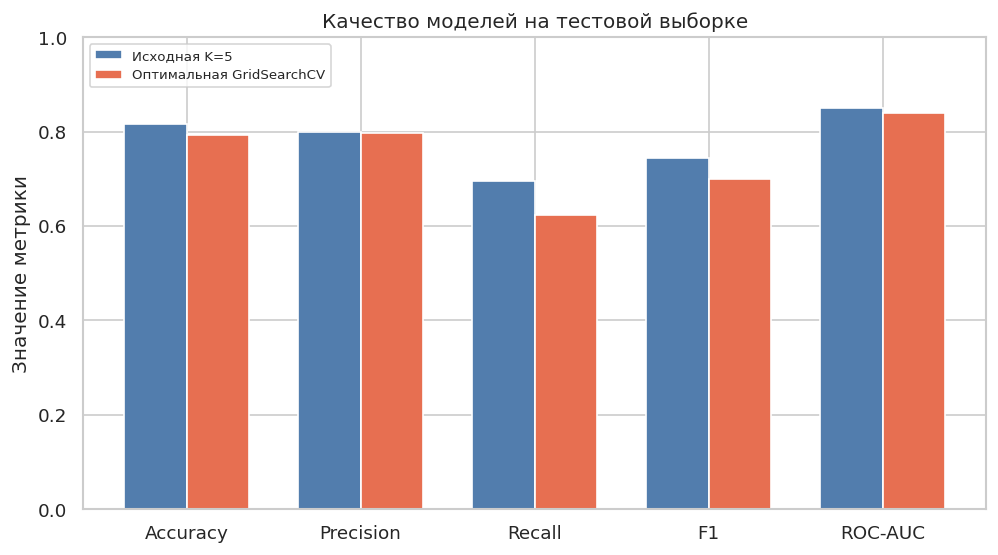

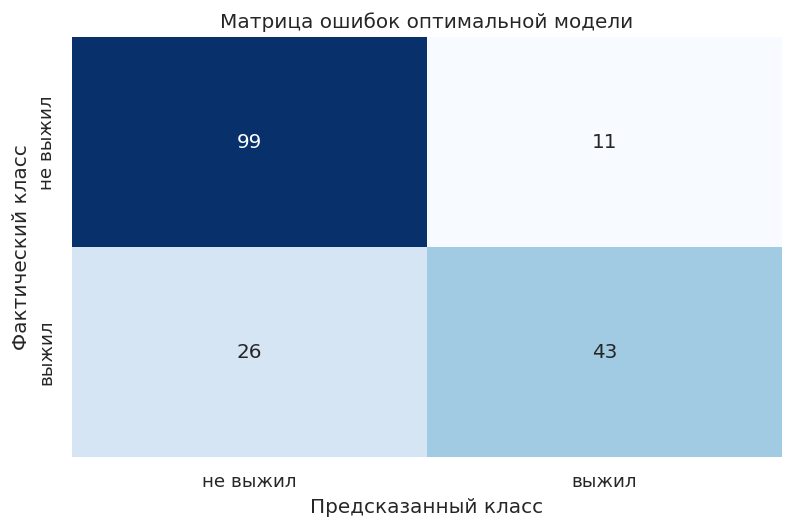

In [8]:
# Визуальное сравнение метрик и матриц ошибок
metric_names = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
positions = np.arange(len(metric_names))
width = 0.36
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.bar(positions - width / 2,
       [baseline_metrics[name] for name in metric_names], width,
       label="Исходная K=5", color="#527dad")
ax.bar(positions + width / 2,
       [best_metrics[name] for name in metric_names], width,
       label=f"Оптимальная {best_search_name}", color="#e76f51")
ax.set_xticks(positions, metric_names)
ax.set_ylim(0, 1)
ax.set_title("Качество моделей на тестовой выборке")
ax.set_ylabel("Значение метрики")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.8, 4.6))
cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["не выжил", "выжил"],
            yticklabels=["не выжил", "выжил"], ax=ax)
ax.set_title("Матрица ошибок оптимальной модели")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Фактический класс")
plt.tight_layout()
plt.show()

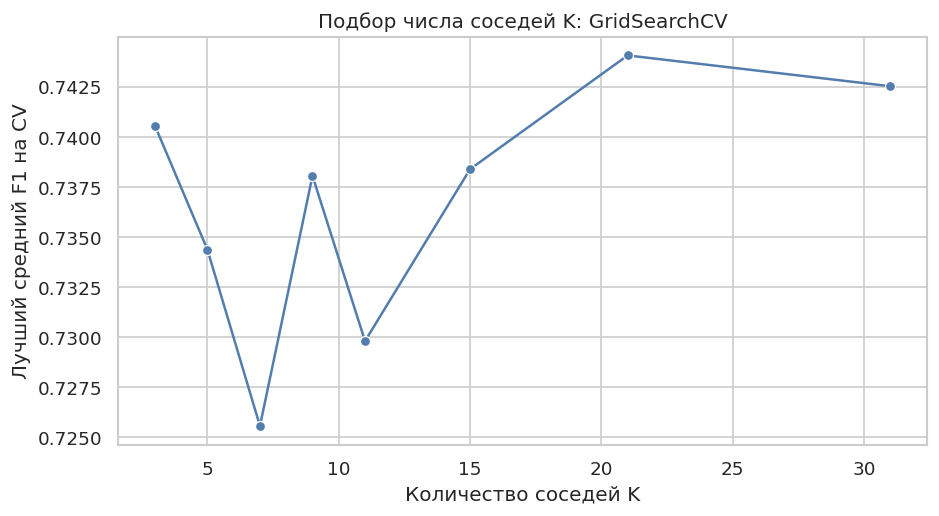

,Стратегия,Поиск,Лучший CV F1,K
0,StratifiedKFold (5 folds),GridSearchCV,0.7441,21
1,RepeatedStratifiedKFold (5x2),RandomizedSearchCV,0.7433,19


Сравнение средних оценок кросс-валидации:


In [9]:
# График среднего CV F1 по K для GridSearchCV
cv_results = pd.DataFrame(grid_search.cv_results_)
by_k = (cv_results.groupby("param_knn__n_neighbors", as_index=False)["mean_test_score"]
        .max().sort_values("param_knn__n_neighbors"))
plt.figure(figsize=(8, 4.5))
sns.lineplot(data=by_k, x="param_knn__n_neighbors", y="mean_test_score",
             marker="o", color="#527dad")
plt.title("Подбор числа соседей K: GridSearchCV")
plt.xlabel("Количество соседей K")
plt.ylabel("Лучший средний F1 на CV")
plt.tight_layout()
plt.show()

print("Сравнение средних оценок кросс-валидации:")
display(pd.DataFrame({
    "Стратегия": ["StratifiedKFold (5 folds)", "RepeatedStratifiedKFold (5x2)"],
    "Поиск": ["GridSearchCV", "RandomizedSearchCV"],
    "Лучший CV F1": [grid_best_score, random_best_score],
    "K": [grid_best_params["knn__n_neighbors"], random_best_params["knn__n_neighbors"]]
}).round(4))

In [10]:
# Сохраняем ключевые результаты для отчёта и повторного использования
results = {
    "rows": int(len(data)),
    "columns": int(data.shape[1]),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "baseline_params": {"n_neighbors": 5, "weights": "uniform", "metric": "euclidean"},
    "baseline_metrics": {k: float(v) for k, v in baseline_metrics.items()},
    "grid_cv_f1": float(grid_best_score),
    "grid_params": {k: (int(v) if isinstance(v, (np.integer,)) else v) for k, v in grid_best_params.items()},
    "random_cv_f1": float(random_best_score),
    "random_params": {k: (int(v) if isinstance(v, (np.integer,)) else v) for k, v in random_best_params.items()},
    "best_search": best_search_name,
    "best_params": {k: (int(v) if isinstance(v, (np.integer,)) else v) for k, v in best_search.best_params_.items()},
    "best_metrics": {k: float(v) for k, v in best_metrics.items()},
    "best_confusion_matrix": confusion_matrix(y_test, best_pred).tolist()
}
print(json.dumps(results, ensure_ascii=False, indent=2))

{
  "rows": 891,
  "columns": 15,
  "train_rows": 712,
  "test_rows": 179,
  "baseline_params": {
    "n_neighbors": 5,
    "weights": "uniform",
    "metric": "euclidean"
  },
  "baseline_metrics": {
    "Accuracy": 0.8156424581005587,
    "Precision": 0.8,
    "Recall": 0.6956521739130435,
    "F1": 0.7441860465116279,
    "ROC-AUC": 0.8495388669301713
  },
  "grid_cv_f1": 0.7440596754675066,
  "grid_params": {
    "knn__metric": "euclidean",
    "knn__n_neighbors": 21,
    "knn__weights": "uniform"
  },
  "random_cv_f1": 0.7433492495799716,
  "random_params": {
    "knn__metric": "minkowski",
    "knn__n_neighbors": 19,
    "knn__p": 1,
    "knn__weights": "uniform"
  },
  "best_search": "GridSearchCV",
  "best_params": {
    "knn__metric": "euclidean",
    "knn__n_neighbors": 21,
    "knn__weights": "uniform"
  },
  "best_metrics": {
    "Accuracy": 0.7932960893854749,
    "Precision": 0.7962962962962963,
    "Recall": 0.6231884057971014,
    "F1": 0.6991869918699187,
    "ROC-AUC"

## 8. Вывод

Итоговые числовые значения формируются при выполнении кода ниже. В выводе сопоставляются качество базовой модели и оптимизированной модели, а также приводятся выбранные параметры и ограничения метода KNN.